In [1]:
import glob
import os

import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

### Helpers

The 4 pixel skin rules from the lab sheet (inlined from `skin_models.py`) and the small helpers used by all three tasks.
Every rule takes a BGR image (as `cv2.imread` gives it) and returns a mask: 255 = skin, 0 = non-skin.

1. **RGB**: R > 95, G > 40, B > 20, max - min > 15, |R - G| > 15, R > G, R > B
2. **HSV**: 0 <= H <= 50 degrees, 0.23 <= S <= 0.68, 0.35 <= V <= 1
3. **YCbCr**: Y > 80, 85 <= Cb <= 135, 135 <= Cr <= 180
4. **Kolkur et al.**: (RGB part AND HSV part) OR (RGB part AND YCbCr polygon)

In [2]:
# colour conversions used by the rules

def split_rgb(img_bgr):
    # float32 R, G, B planes (0..255) from a BGR uint8 image
    img = img_bgr.astype(np.float32)
    b, g, r = img[:, :, 0], img[:, :, 1], img[:, :, 2]
    return r, g, b


def bgr_to_ycbcr(img_bgr):
    # RGB -> YCbCr with the JPEG formulas from the lab sheet, float32 in 0..255
    r, g, b = split_rgb(img_bgr)
    y = 0.299 * r + 0.587 * g + 0.114 * b
    cb = -0.1687 * r - 0.3313 * g + 0.5 * b + 128.0
    cr = 0.5 * r - 0.4187 * g - 0.0813 * b + 128.0
    return np.clip(y, 0, 255), np.clip(cb, 0, 255), np.clip(cr, 0, 255)


def bgr_to_hsv_float(img_bgr):
    # on a float32 image OpenCV gives H in degrees [0, 360) and S, V in [0, 1]
    # (on uint8 it stores H/2 in 0..179 and S, V in 0..255)
    img = img_bgr.astype(np.float32) / 255.0
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    return hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]


def to_mask(boolean_array):
    # bool HxW -> uint8 HxW, 255 = skin
    return (boolean_array.astype(np.uint8)) * 255

In [3]:
# the raw rules (boolean arrays), so they can be combined in method 4

def rgb_rule(r, g, b):
    # rule 1 from the lab sheet (Kovac / Peer RGB rule)
    mx = np.maximum(np.maximum(r, g), b)
    mn = np.minimum(np.minimum(r, g), b)
    return ((r > 95) & (g > 40) & (b > 20)
            & ((mx - mn) > 15)
            & (np.abs(r - g) > 15)
            & (r > g) & (r > b))


def hsv_rule(h, s, v):
    # rule 2: h in degrees, s and v in 0..1
    return (h >= 0) & (h <= 50) & (s >= 0.23) & (s <= 0.68) & (v >= 0.35) & (v <= 1.0)


def ycbcr_rule(y, cb, cr):
    # rule 3
    return (y > 80) & (cb >= 85) & (cb <= 135) & (cr >= 135) & (cr <= 180)


def kolkur_rgb_part(r, g, b):
    # RGB part of the Kolkur et al. rule (no max - min test here)
    return ((r > 95) & (g > 40) & (b > 20)
            & (r > g) & (r > b)
            & (np.abs(r - g) > 15))


def kolkur_hsv_part(h, s):
    return (h >= 0.0) & (h <= 50.0) & (s >= 0.23) & (s <= 0.68)


def kolkur_ycbcr_part(y, cb, cr):
    # YCbCr polygon of Kolkur et al. (section 4 of the paper)
    return ((cr > 135) & (cb > 85) & (y > 80)
            & (cr <= 1.5862 * cb + 20)
            & (cr >= 0.3448 * cb + 76.2069)
            & (cr >= -4.5652 * cb + 234.5652)
            & (cr <= -1.15 * cb + 301.75)
            & (cr <= -2.2857 * cb + 432.85))

In [4]:
# the 4 classifiers required by the lab

def skin_rgb(img_bgr):
    r, g, b = split_rgb(img_bgr)
    return to_mask(rgb_rule(r, g, b))


def skin_hsv(img_bgr):
    h, s, v = bgr_to_hsv_float(img_bgr)
    return to_mask(hsv_rule(h, s, v))


def skin_ycbcr(img_bgr):
    # our own RGB -> YCbCr conversion (lab formulas), not cv2
    y, cb, cr = bgr_to_ycbcr(img_bgr)
    return to_mask(ycbcr_rule(y, cb, cr))


def skin_kolkur(img_bgr):
    # skin = (HSV part AND RGB part) OR (RGB part AND YCbCr polygon)
    # the paper's alpha test A > 15 is always true for JPEG, so it is dropped
    r, g, b = split_rgb(img_bgr)
    h, s, _ = bgr_to_hsv_float(img_bgr)
    y, cb, cr = bgr_to_ycbcr(img_bgr)
    rgb_ok = kolkur_rgb_part(r, g, b)
    skin = (kolkur_hsv_part(h, s) & rgb_ok) | (rgb_ok & kolkur_ycbcr_part(y, cb, cr))
    return to_mask(skin)


# name -> function, in the order the lab lists them
METHODS = {
    'rgb': skin_rgb,
    'hsv': skin_hsv,
    'ycbcr': skin_ycbcr,
    'kolkur': skin_kolkur,
}

METHOD_TITLES = {
    'rgb': '1) RGB rule',
    'hsv': '2) HSV rule',
    'ycbcr': '3) YCbCr rule',
    'kolkur': '4) Kolkur RGB+HSV+YCbCr',
}

In [5]:
# data folders, file helpers and the evaluation metrics

SKIN_DIR = 'data/skin'
PRATHEEPAN = {
    'FacePhoto': ('data/Pratheepan_Dataset/FacePhoto', 'data/Ground_Truth/GroundT_FacePhoto'),
    'FamilyPhoto': ('data/Pratheepan_Dataset/FamilyPhoto', 'data/Ground_Truth/GroundT_FamilyPhoto'),
}
IMAGE_EXT = ('.jpg', '.jpeg', '.png', '.bmp')


def list_images(folder):
    files = [p for p in glob.glob(os.path.join(folder, '*')) if p.lower().endswith(IMAGE_EXT)]
    return sorted(files, key=lambda p: os.path.basename(p).lower())


def stem(path):
    return os.path.splitext(os.path.basename(path))[0]


def bgr_to_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def load_gt_mask(gt_path, image_shape):
    # ground truth png -> bool HxW (True = skin)
    # gray + threshold 128 handles 3/4-channel PNGs and anti-aliased gray pixels
    gt = cv2.imread(gt_path, cv2.IMREAD_COLOR)  # drops the alpha channel if any
    gray = cv2.cvtColor(gt, cv2.COLOR_BGR2GRAY)
    if gray.shape[:2] != image_shape[:2]:
        print(f'   WARNING: GT {os.path.basename(gt_path)} has shape {gray.shape[:2]}, '
              f'image has {image_shape[:2]} -> resizing GT')
        gray = cv2.resize(gray, (image_shape[1], image_shape[0]), interpolation=cv2.INTER_NEAREST)
    return gray >= 128


def confusion_counts(pred_mask, gt_bool):
    # TP, FN, FP, TN pixel counts for one image
    pred = pred_mask > 0
    tp = int(np.count_nonzero(pred & gt_bool))
    fn = int(np.count_nonzero(~pred & gt_bool))
    fp = int(np.count_nonzero(pred & ~gt_bool))
    tn = int(np.count_nonzero(~pred & ~gt_bool))
    return tp, fn, fp, tn


def metrics(tp, fn, fp, tn):
    total = tp + fn + fp + tn
    acc = (tp + tn) / total if total else 0.0
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return acc, prec, rec, f1


def draw_confusion(ax, title, tp, fn, fp, tn):
    # 2x2 confusion matrix in the lab layout: rows = ground truth, cols = predicted
    acc, prec, rec, f1 = metrics(tp, fn, fp, tn)
    mat = np.array([[tp, fn], [fp, tn]], dtype=np.float64)
    perc = mat / mat.sum() * 100.0
    ax.imshow(perc, cmap='Blues', vmin=0, vmax=100)
    labels = [['TP', 'FN'], ['FP', 'TN']]
    for i in range(2):
        for j in range(2):
            color = 'white' if perc[i, j] > 50 else 'black'
            ax.text(j, i, f'{labels[i][j]}\n{int(mat[i, j]):,}\n({perc[i, j]:.1f}%)',
                    ha='center', va='center', color=color, fontsize=10)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Skin', 'Non-skin'])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Skin', 'Non-skin'])
    ax.set_xlabel('Predicted by the method')
    ax.set_ylabel('Ground truth')
    ax.set_title(f'{title}\naccuracy = {acc:.4f}\nprecision={prec:.3f}  recall={rec:.3f}  F1={f1:.3f}',
                 fontsize=10)

---

### a) **Skin masks on the 12 test images**

The 4 rules are applied to every image in `data/skin`. First, the channels the rules look at
(one colormap per channel, like in the lab notebook), then the 4 masks of every image.

In [6]:
test_images = list_images(SKIN_DIR)
print(len(test_images), 'test images:', ', '.join(stem(p) for p in test_images))

12 test images: 1, 2, 3, 4, 5, group, group2, hands3, manwoman, t26, t27, t63


#### The channels used by the RGB, HSV and YCbCr rules

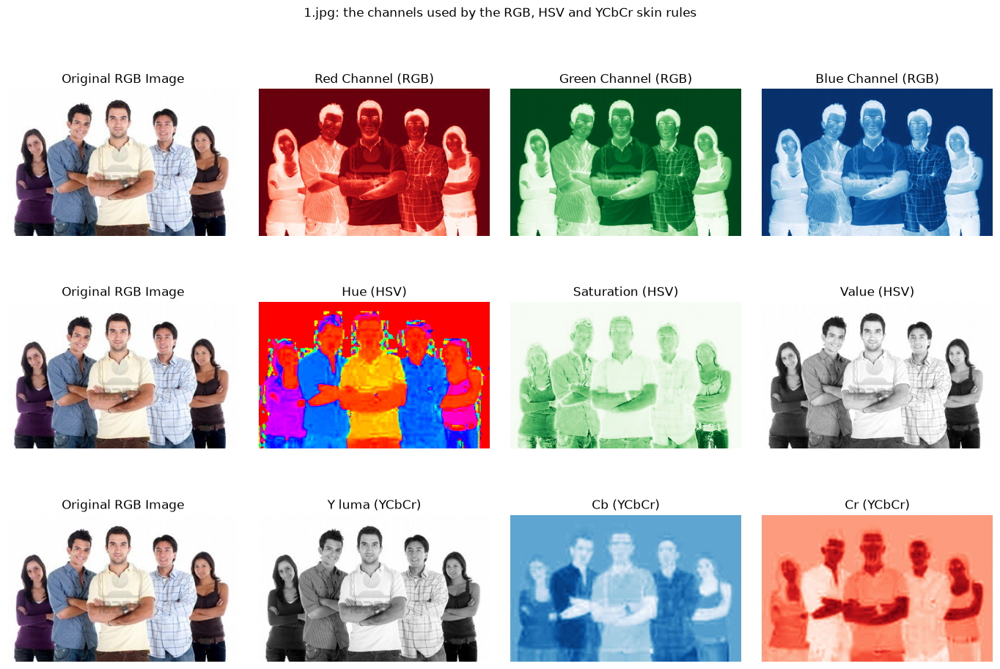

In [7]:
img = cv2.imread(os.path.join(SKIN_DIR, '1.jpg'))
img_rgb = bgr_to_rgb(img)
r_channel, g_channel, b_channel = img_rgb[:, :, 0], img_rgb[:, :, 1], img_rgb[:, :, 2]
h_channel, s_channel, v_channel = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2HSV))
y_channel, cr_channel, cb_channel = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2YCR_CB))

panels = [
    [('Original RGB Image', img_rgb, None), ('Red Channel (RGB)', r_channel, 'Reds'),
     ('Green Channel (RGB)', g_channel, 'Greens'), ('Blue Channel (RGB)', b_channel, 'Blues')],
    [('Original RGB Image', img_rgb, None), ('Hue (HSV)', h_channel, 'hsv'),
     ('Saturation (HSV)', s_channel, 'Greens'), ('Value (HSV)', v_channel, 'gray')],
    [('Original RGB Image', img_rgb, None), ('Y luma (YCbCr)', y_channel, 'gray'),
     ('Cb (YCbCr)', cb_channel, 'Blues'), ('Cr (YCbCr)', cr_channel, 'Reds')],
]

fig, axs = plt.subplots(3, 4, figsize=(14, 10))
for row, ax_row in zip(panels, axs):
    for ax, (title, channel, cmap) in zip(ax_row, row):
        ax.imshow(channel, cmap=cmap)
        ax.set_title(title)
        ax.axis('off')
fig.suptitle('1.jpg: the channels used by the RGB, HSV and YCbCr skin rules')
plt.tight_layout(pad=2.0)
plt.show()

**Result:** skin is bright in R and in Cr, has a low hue (red-orange) and a middle saturation.
That is exactly what the 4 rules test.

#### The 4 masks of every test image

In [8]:
# masks of the 4 methods for every test image
imgs_a = {}
masks_a = {}
for path in test_images:
    img = cv2.imread(path)
    name = stem(path)
    imgs_a[name] = img
    masks_a[name] = {m: fn(img) for m, fn in METHODS.items()}


def show_mask_grid(names, title):
    # rows = images, cols = original + the 4 masks
    fig, axs = plt.subplots(len(names), 5, figsize=(17, 3.3 * len(names)))
    for ax_row, name in zip(axs, names):
        img = imgs_a[name]
        ax_row[0].imshow(bgr_to_rgb(img))
        ax_row[0].set_title(f'{name} ({img.shape[1]}x{img.shape[0]})')
        for ax, m in zip(ax_row[1:], METHODS):
            mask = masks_a[name][m]
            pct = 100.0 * np.count_nonzero(mask) / mask.size
            ax.imshow(mask, cmap='gray', vmin=0, vmax=255)
            ax.set_title(f'{METHOD_TITLES[m]}\n{pct:.1f}% skin', fontsize=9)
        for ax in ax_row:
            ax.axis('off')
    fig.suptitle(title, fontsize=13)
    plt.tight_layout(rect=(0, 0, 1, 0.98))
    plt.show()


names_a = list(imgs_a)

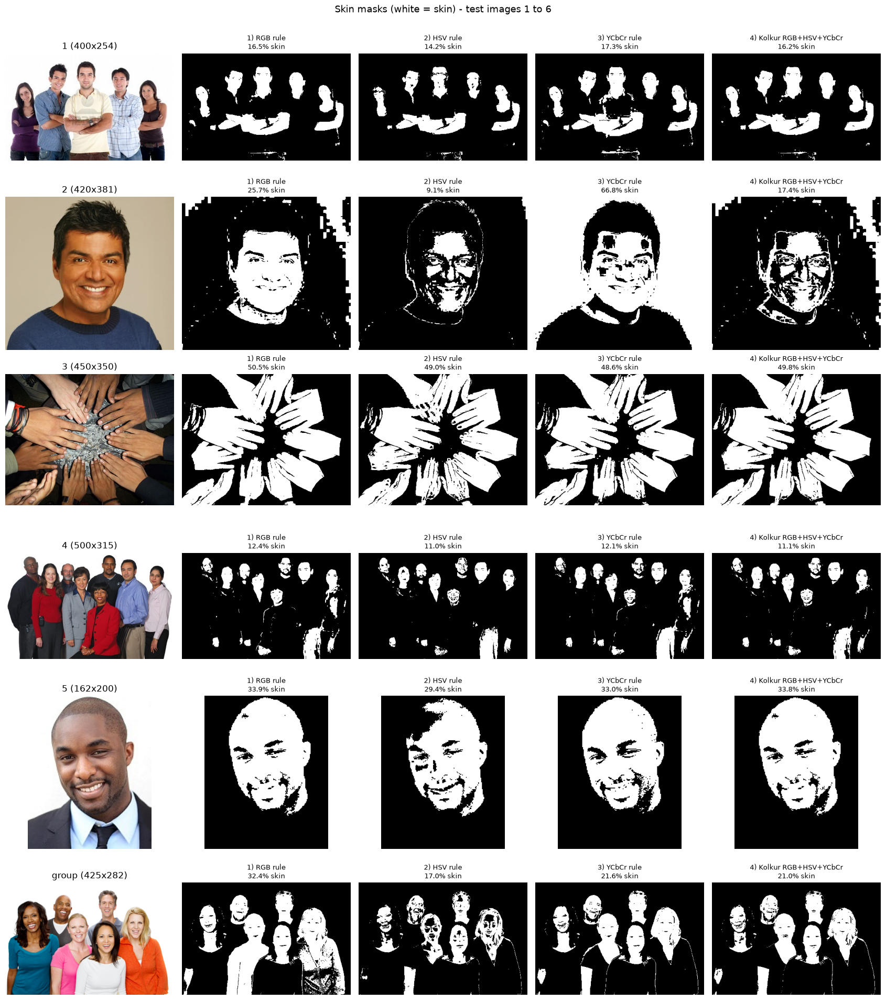

In [9]:
show_mask_grid(names_a[:6], 'Skin masks (white = skin) - test images 1 to 6')

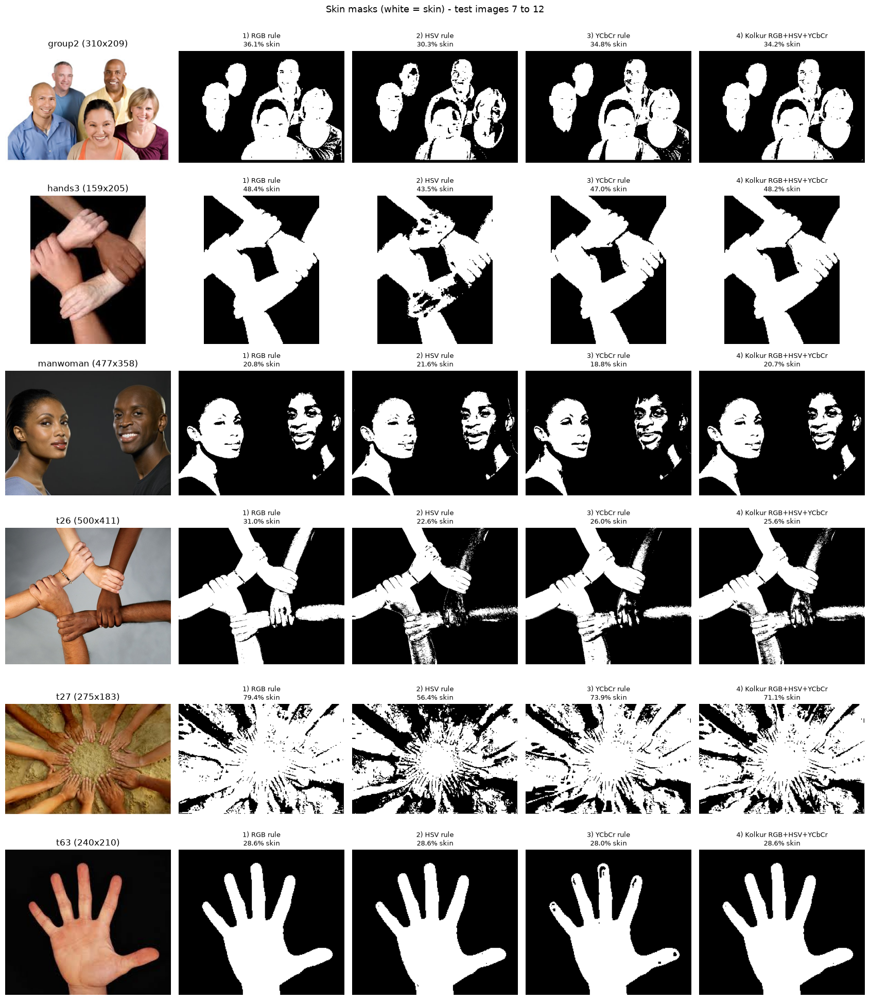

In [10]:
show_mask_grid(names_a[6:], 'Skin masks (white = skin) - test images 7 to 12')

In [11]:
# percentage of pixels classified as skin, per image and method
lines = ['| Image | Size | ' + ' | '.join(METHOD_TITLES[m] for m in METHODS) + ' |',
         '|---|---|' + '---:|' * len(METHODS)]
for name, img in imgs_a.items():
    pcts = [100.0 * np.count_nonzero(masks_a[name][m]) / masks_a[name][m].size for m in METHODS]
    lines.append(f'| {name} | {img.shape[1]}x{img.shape[0]} | ' + ' | '.join(f'{p:.1f}%' for p in pcts) + ' |')
display(Markdown('\n'.join(lines)))

| Image | Size | 1) RGB rule | 2) HSV rule | 3) YCbCr rule | 4) Kolkur RGB+HSV+YCbCr |
|---|---|---:|---:|---:|---:|
| 1 | 400x254 | 16.5% | 14.2% | 17.3% | 16.2% |
| 2 | 420x381 | 25.7% | 9.1% | 66.8% | 17.4% |
| 3 | 450x350 | 50.5% | 49.0% | 48.6% | 49.8% |
| 4 | 500x315 | 12.4% | 11.0% | 12.1% | 11.1% |
| 5 | 162x200 | 33.9% | 29.4% | 33.0% | 33.8% |
| group | 425x282 | 32.4% | 17.0% | 21.6% | 21.0% |
| group2 | 310x209 | 36.1% | 30.3% | 34.8% | 34.2% |
| hands3 | 159x205 | 48.4% | 43.5% | 47.0% | 48.2% |
| manwoman | 477x358 | 20.8% | 21.6% | 18.8% | 20.7% |
| t26 | 500x411 | 31.0% | 22.6% | 26.0% | 25.6% |
| t27 | 275x183 | 79.4% | 56.4% | 73.9% | 71.1% |
| t63 | 240x210 | 28.6% | 28.6% | 28.0% | 28.6% |

In [12]:
# sanity check of our YCbCr conversion against OpenCV (not used for the masks)
img = cv2.imread(test_images[0])
y, cb, cr = bgr_to_ycbcr(img)
ycrcb = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb).astype(np.float32)
diff = max(np.abs(y - ycrcb[:, :, 0]).max(), np.abs(cr - ycrcb[:, :, 1]).max(),
           np.abs(cb - ycrcb[:, :, 2]).max())
print(f'max |our YCbCr - cv2 YCrCb| on {stem(test_images[0])} = {diff:.2f} '
      '(small: cv2 uses the same JPEG formulas, rounded to uint8)')

max |our YCbCr - cv2 YCrCb| on 1 = 0.80 (small: cv2 uses the same JPEG formulas, rounded to uint8)


**Result:**
- On clean images (3, 4, 5, hands3, t63) the four methods agree almost perfectly.
- RGB is the most permissive: in `group.jpg` it marks the pink and orange T-shirts as skin (32% vs 17-22%).
- YCbCr accepts the whole brownish background of `2.jpg` (67% skin): the Cb/Cr window is wide and there is no hue limit.
- HSV is the strictest (S >= 0.23 rejects pale or very bright skin); Kolkur is in between.
- Our YCbCr formulas match OpenCV within 0.80 (OpenCV rounds to uint8).

---

### b) **Evaluation on the Pratheepan dataset**

The pixels of all images are counted together (TP, FN, FP, TN summed over the whole set),
then the confusion matrix and the metrics are computed from the sums.

|                 | Predicted skin | Predicted non-skin |
|---|---|---|
| **GT skin**     | TP | FN |
| **GT non-skin** | FP | TN |

Accuracy = (TP + TN) / (TP + FN + FP + TN). Bonus: precision = TP/(TP+FP), recall = TP/(TP+FN), F1 = 2PR/(P+R).

In [13]:
def evaluate_dataset(set_name, img_dir, gt_dir):
    # sum TP/FN/FP/TN of every method over all image/GT pairs of one subset
    totals = {m: np.zeros(4, dtype=np.int64) for m in METHODS}
    images = {stem(p): p for p in list_images(img_dir)}
    gts = {stem(p): p for p in list_images(gt_dir)}

    for g in sorted(set(gts) - set(images)):
        print(f'   note: GT {os.path.basename(gts[g])} has no image in {set_name} -> skipped')
    for i in sorted(set(images) - set(gts)):
        print(f'   note: image {os.path.basename(images[i])} has no GT in {set_name} -> skipped')

    common = sorted(set(images) & set(gts))
    print(f'{set_name}: {len(common)} image/GT pairs')
    for name in common:
        img = cv2.imread(images[name])
        if img is None:
            print('   cannot read', images[name])
            continue
        gt = load_gt_mask(gts[name], img.shape)
        for m, fn in METHODS.items():
            totals[m] += np.array(confusion_counts(fn(img), gt), dtype=np.int64)
    return totals, len(common)


results = {}    # set name -> {method -> [tp, fn, fp, tn]}
n_images = {}
for set_name, (img_dir, gt_dir) in PRATHEEPAN.items():
    results[set_name], n_images[set_name] = evaluate_dataset(set_name, img_dir, gt_dir)

results['Combined'] = {m: sum(results[s][m] for s in PRATHEEPAN) for m in METHODS}
n_images['Combined'] = sum(n_images[s] for s in PRATHEEPAN)

FacePhoto: 32 image/GT pairs


FamilyPhoto: 46 image/GT pairs


In [14]:
def metrics_table(set_names):
    lines = ['| Set | Method | TP | FN | FP | TN | Accuracy | Precision | Recall | F1 |',
             '|---|---|---:|---:|---:|---:|---:|---:|---:|---:|']
    for s in set_names:
        pixels = int(results[s]['rgb'].sum())
        for m in METHODS:
            tp, fn, fp, tn = (int(v) for v in results[s][m])
            acc, prec, rec, f1 = metrics(tp, fn, fp, tn)
            lines.append(f'| {s} ({n_images[s]} img, {pixels / 1e6:.1f} M px) | {METHOD_TITLES[m]} | '
                         f'{tp:,} | {fn:,} | {fp:,} | {tn:,} | **{acc:.4f}** | {prec:.4f} | {rec:.4f} | {f1:.4f} |')
    return '\n'.join(lines)


display(Markdown('**All Pratheepan images (FacePhoto + FamilyPhoto)**\n\n' + metrics_table(['Combined'])))

**All Pratheepan images (FacePhoto + FamilyPhoto)**

| Set | Method | TP | FN | FP | TN | Accuracy | Precision | Recall | F1 |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Combined (78 img, 18.8 M px) | 1) RGB rule | 2,791,066 | 359,417 | 3,662,329 | 11,985,941 | **0.7861** | 0.4325 | 0.8859 | 0.5812 |
| Combined (78 img, 18.8 M px) | 2) HSV rule | 2,399,625 | 750,858 | 2,540,892 | 13,107,378 | **0.8249** | 0.4857 | 0.7617 | 0.5932 |
| Combined (78 img, 18.8 M px) | 3) YCbCr rule | 2,686,156 | 464,327 | 3,376,805 | 12,271,465 | **0.7957** | 0.4430 | 0.8526 | 0.5831 |
| Combined (78 img, 18.8 M px) | 4) Kolkur RGB+HSV+YCbCr | 2,686,943 | 463,540 | 2,963,278 | 12,684,992 | **0.8177** | 0.4755 | 0.8529 | 0.6106 |

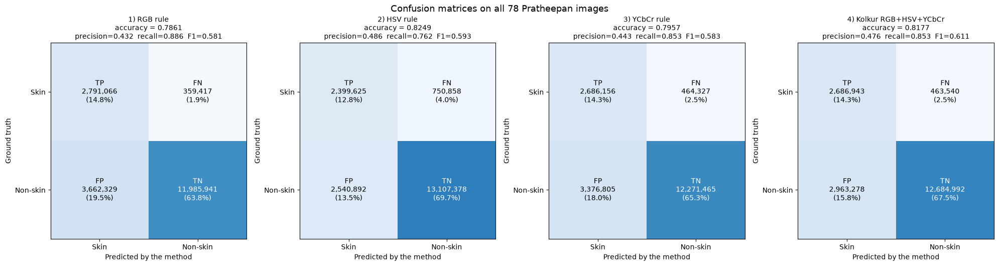

In [15]:
fig, axs = plt.subplots(1, 4, figsize=(20, 5.2))
for ax, m in zip(axs, METHODS):
    tp, fn, fp, tn = (int(v) for v in results['Combined'][m])
    draw_confusion(ax, METHOD_TITLES[m], tp, fn, fp, tn)
fig.suptitle(f'Confusion matrices on all {n_images["Combined"]} Pratheepan images', fontsize=13)
plt.tight_layout()
plt.show()

#### Per subset: FacePhoto (close portraits) and FamilyPhoto (groups, complex backgrounds)

In [16]:
display(Markdown(metrics_table(['FacePhoto', 'FamilyPhoto'])))

| Set | Method | TP | FN | FP | TN | Accuracy | Precision | Recall | F1 |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| FacePhoto (32 img, 5.9 M px) | 1) RGB rule | 1,404,188 | 147,706 | 1,150,217 | 3,211,196 | **0.7805** | 0.5497 | 0.9048 | 0.6839 |
| FacePhoto (32 img, 5.9 M px) | 2) HSV rule | 1,188,525 | 363,369 | 931,382 | 3,430,031 | **0.7810** | 0.5606 | 0.7659 | 0.6474 |
| FacePhoto (32 img, 5.9 M px) | 3) YCbCr rule | 1,386,002 | 165,892 | 1,017,973 | 3,343,440 | **0.7998** | 0.5765 | 0.8931 | 0.7007 |
| FacePhoto (32 img, 5.9 M px) | 4) Kolkur RGB+HSV+YCbCr | 1,347,608 | 204,286 | 995,875 | 3,365,538 | **0.7970** | 0.5750 | 0.8684 | 0.6919 |
| FamilyPhoto (46 img, 12.9 M px) | 1) RGB rule | 1,386,878 | 211,711 | 2,512,112 | 8,774,745 | **0.7886** | 0.3557 | 0.8676 | 0.5045 |
| FamilyPhoto (46 img, 12.9 M px) | 2) HSV rule | 1,211,100 | 387,489 | 1,609,510 | 9,677,347 | **0.8450** | 0.4294 | 0.7576 | 0.5481 |
| FamilyPhoto (46 img, 12.9 M px) | 3) YCbCr rule | 1,300,154 | 298,435 | 2,358,832 | 8,928,025 | **0.7938** | 0.3553 | 0.8133 | 0.4946 |
| FamilyPhoto (46 img, 12.9 M px) | 4) Kolkur RGB+HSV+YCbCr | 1,339,335 | 259,254 | 1,967,403 | 9,319,454 | **0.8272** | 0.4050 | 0.8378 | 0.5461 |

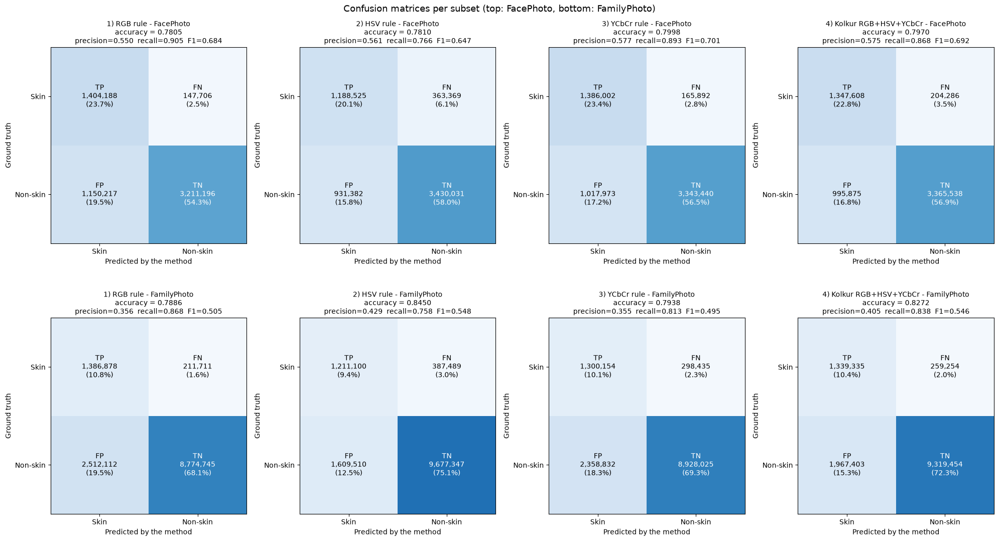

In [17]:
fig, axs = plt.subplots(2, 4, figsize=(20, 11))
for ax_row, set_name in zip(axs, PRATHEEPAN):
    for ax, m in zip(ax_row, METHODS):
        tp, fn, fp, tn = (int(v) for v in results[set_name][m])
        draw_confusion(ax, f'{METHOD_TITLES[m]} - {set_name}', tp, fn, fp, tn)
fig.suptitle('Confusion matrices per subset (top: FacePhoto, bottom: FamilyPhoto)', fontsize=13)
plt.tight_layout(h_pad=3)
plt.show()

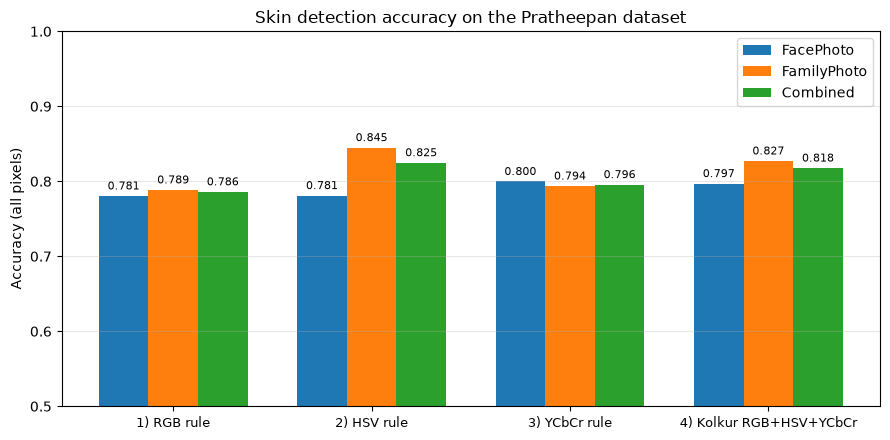

In [18]:
# accuracy of every method on every subset
fig, ax = plt.subplots(figsize=(9, 4.5))
width = 0.25
x = np.arange(len(METHODS))
for k, set_name in enumerate(results):
    accs = [metrics(*results[set_name][m])[0] for m in METHODS]
    bars = ax.bar(x + (k - 1) * width, accs, width, label=set_name)
    for bar, a in zip(bars, accs):
        ax.text(bar.get_x() + bar.get_width() / 2, a + 0.005, f'{a:.3f}',
                ha='center', va='bottom', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([METHOD_TITLES[m] for m in METHODS], fontsize=9)
ax.set_ylim(0.5, 1.0)
ax.set_ylabel('Accuracy (all pixels)')
ax.set_title('Skin detection accuracy on the Pratheepan dataset')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
best_method = max(METHODS, key=lambda m: metrics(*results['Combined'][m])[0])
tp, fn, fp, tn = (int(v) for v in results['Combined'][best_method])
total = tp + fn + fp + tn
print(f'best method by combined accuracy: {METHOD_TITLES[best_method]}')
print(f'accuracy = (TP + TN) / total = ({tp:,} + {tn:,}) / {total:,} = {(tp + tn) / total:.4f}')
print(f'share of skin pixels in the ground truth: {(tp + fn) / total:.1%}')

best method by combined accuracy: 2) HSV rule
accuracy = (TP + TN) / total = (2,399,625 + 13,107,378) / 18,798,753 = 0.8249
share of skin pixels in the ground truth: 16.8%


**Result:** by accuracy the **HSV rule is the best: 0.8249** on all 78 images (0.8450 on FamilyPhoto, 0.7810 on FacePhoto).
Kolkur is a close second (0.8177) and has the best F1 (0.611); YCbCr (0.796) and RGB (0.786) are the weakest.
Why: only about 17% of the pixels are skin, so accuracy is decided by the non-skin pixels and the method with the
fewest false positives wins. HSV has the fewest FP (2.5 M) thanks to its hue and saturation limits; the price is the
lowest recall (0.76). On FacePhoto alone the methods are close (0.78-0.80) and YCbCr is marginally best.

---

### c) **Face detection from the skin mask (no built-in detector)**

1. Skin mask of the best method from b) (HSV).
2. Morphological opening then closing (elliptical kernel, about 1.5% of the shorter side) to remove specks and fill small holes.
3. Connected components; each blob gets a score = area x aspect bonus x position bonus x hole bonus
   (a face has holes for eyes, eyebrows and mouth, an arm does not). The best blob is kept.
4. The blob is cut at the neck: going down, the first row where the blob width falls under 65% of the widest row so far.
5. Bounding box of the head part -> minimal square (side = max(w, h), centred, clipped to the image), drawn with `cv2.rectangle`.

In [20]:
def clean_mask(mask):
    # morphological opening (remove specks) then closing (fill holes)
    h, w = mask.shape
    k = max(3, int(round(min(h, w) * 0.015)) | 1)      # odd kernel, ~1.5% of the short side
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    opened = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)
    return closed


def count_holes(blob_crop, min_area):
    # holes (eyes, eyebrows, mouth...) = non-skin regions that do not touch the crop border
    inv = (~blob_crop).astype(np.uint8)
    n, _, stats, _ = cv2.connectedComponentsWithStats(inv, connectivity=4)
    h, w = inv.shape
    holes = 0
    for i in range(1, n):
        x, y, ww, hh, area = stats[i]
        touches_border = x == 0 or y == 0 or x + ww == w or y + hh == h
        if not touches_border and area >= min_area:
            holes += 1
    return holes


def pick_face_blob(clean):
    # score = area * aspect_bonus * position_bonus * hole_bonus
    #   aspect_bonus   = 1.0 if 0.3 <= w/h <= 1.6 else 0.5
    #   position_bonus = 1.0 if the blob centre is in the upper 60% of the image else 0.7
    #   hole_bonus     = 1 + 0.5 * min(holes, 3)
    # returns the boolean mask of the chosen blob, or None if there is no skin at all
    n, labels, stats, centroids = cv2.connectedComponentsWithStats(clean, connectivity=8)
    if n <= 1:
        return None
    img_h, img_w = clean.shape
    min_area = 0.002 * img_h * img_w
    best, best_score = None, -1.0
    for i in range(1, n):                       # label 0 is the background
        x, y, w, h, area = stats[i]
        if area < min_area:
            continue
        aspect = w / float(h)
        blob_crop = labels[y:y + h, x:x + w] == i
        holes = count_holes(blob_crop, max(9, 0.004 * area))
        score = float(area)
        score *= 1.0 if 0.3 <= aspect <= 1.6 else 0.5
        score *= 1.0 if centroids[i][1] < 0.6 * img_h else 0.7
        score *= 1.0 + 0.5 * min(holes, 3)
        if score > best_score:
            best_score, best = score, i
    if best is None:                            # everything was tiny: take the largest anyway
        best = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    return labels == best

In [21]:
def head_box_from_blob(blob):
    # width of the blob on every row (left-most to right-most skin pixel, so eye holes do not matter);
    # going down, the first row under 65% of the widest row so far is the neck, accepted only when
    # the part above is at least 0.6 times as tall as it is wide (so we do not cut at the eyebrows)
    rows = np.count_nonzero(blob, axis=1)
    ys = np.flatnonzero(rows)
    top, bottom = int(ys[0]), int(ys[-1])
    part = blob[top:bottom + 1]
    first = np.argmax(part, axis=1)                                 # left-most skin pixel per row
    last = part.shape[1] - 1 - np.argmax(part[:, ::-1], axis=1)     # right-most skin pixel
    prof = (last - first + 1).astype(np.float64)                    # horizontal extent per row
    prof[rows[top:bottom + 1] == 0] = 0
    win = max(3, int(len(prof) * 0.03) | 1)
    prof = np.convolve(prof, np.ones(win) / win, mode='same')
    running_max = np.maximum.accumulate(prof)
    cut = bottom
    for i in range(win, len(prof)):
        if prof[i] < 0.65 * running_max[i] and i >= 0.6 * running_max[i]:
            cut = top + i
            break
    head = blob[top:cut + 1]
    xs = np.flatnonzero(np.any(head, axis=0))
    x0, x1 = int(xs[0]), int(xs[-1])
    return x0, top, x1 - x0 + 1, cut - top + 1


def square_box(x, y, w, h, img_w, img_h):
    # minimal square around the box, centred on it, clipped to the image
    side = max(w, h)
    cx, cy = x + w / 2.0, y + h / 2.0
    x0 = int(round(cx - side / 2.0))
    y0 = int(round(cy - side / 2.0))
    x0 = min(max(0, x0), max(0, img_w - side))
    y0 = min(max(0, y0), max(0, img_h - side))
    x1 = min(img_w - 1, x0 + side - 1)
    y1 = min(img_h - 1, y0 + side - 1)
    return x0, y0, x1, y1


def detect_face(img, method):
    mask = METHODS[method](img)
    clean = clean_mask(mask)
    blob = pick_face_blob(clean)
    if blob is None:
        return mask, clean, None
    x, y, w, h = head_box_from_blob(blob)
    return mask, clean, square_box(x, y, w, h, img.shape[1], img.shape[0])

In [22]:
# all 32 FacePhoto portraits + manwoman.jpg from the test images
portraits = list_images(PRATHEEPAN['FacePhoto'][0]) + [os.path.join(SKIN_DIR, 'manwoman.jpg')]

faces = {}   # name -> (image, raw mask, cleaned mask, square or None, image with the square drawn)
for path in portraits:
    img = cv2.imread(path)
    name = stem(path)
    mask, clean, box = detect_face(img, best_method)
    drawn = img.copy()
    if box is None:
        print(f'{name}: no skin blob found')
    else:
        x0, y0, x1, y1 = box
        thickness = max(2, min(img.shape[:2]) // 150)
        cv2.rectangle(drawn, (x0, y0), (x1, y1), (0, 255, 0), thickness)
        print(f'{name:45s} square = ({x0},{y0})-({x1},{y1}) side={x1 - x0 + 1}')
    faces[name] = (img, mask, clean, box, drawn)

0520962400                                    square = (140,0)-(276,136) side=137
06Apr03Face                                   square = (58,46)-(328,316) side=271
124511719065943_2                             square = (85,132)-(207,254) side=123
920480_f520                                   square = (197,86)-(371,260) side=175
Aishwarya-Rai_20091229_aatheory               square = (76,56)-(283,263) side=208
amida-belly-dancer                            square = (147,48)-(251,152) side=105
chenhao0017me9                                square = (104,97)-(516,509) side=413
dulani_anuradha4                              square = (106,117)-(208,219) side=103
dulani_anuradha7                              square = (26,68)-(182,224) side=157
evangeline-lilly-face-wallpapers_1593_1024    square = (123,4)-(465,346) side=343
gvkM2-eJH8Pl                                  square = (154,84)-(242,172) side=89
josh-hartnett-Poster-thumb                    square = (0,0)-(319,394) side=320
Kishani_-__n

#### The pipeline step by step on one good and one failed portrait

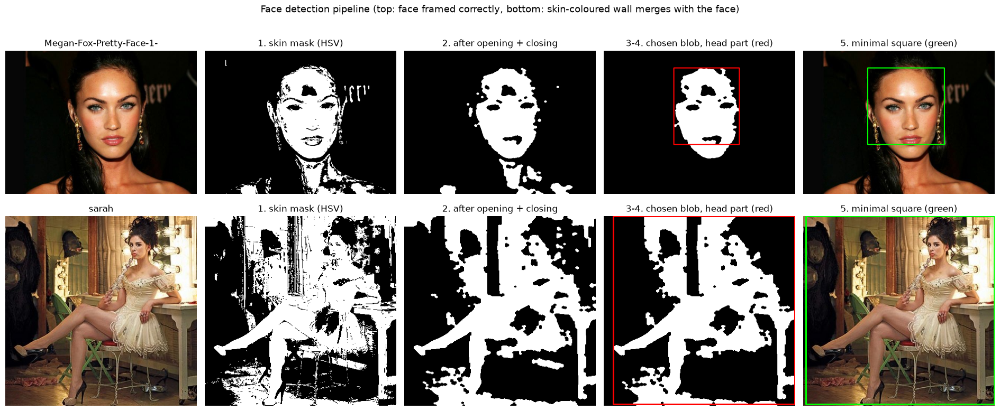

In [23]:
examples = ['Megan-Fox-Pretty-Face-1-1024x768', 'sarah']
fig, axs = plt.subplots(len(examples), 5, figsize=(19, 4 * len(examples)))
for ax_row, name in zip(axs, examples):
    img, mask, clean, box, drawn = faces[name]
    blob = pick_face_blob(clean)
    x, y, w, h = head_box_from_blob(blob)
    blob_vis = cv2.cvtColor(blob.astype(np.uint8) * 255, cv2.COLOR_GRAY2RGB)
    cv2.rectangle(blob_vis, (x, y), (x + w - 1, y + h - 1), (255, 0, 0), max(2, min(img.shape[:2]) // 150))
    steps = [(bgr_to_rgb(img), f'{name[:24]}'), (mask, '1. skin mask (HSV)'),
             (clean, '2. after opening + closing'), (blob_vis, '3-4. chosen blob, head part (red)'),
             (bgr_to_rgb(drawn), '5. minimal square (green)')]
    for ax, (picture, title) in zip(ax_row, steps):
        ax.imshow(picture, cmap='gray' if picture.ndim == 2 else None)
        ax.set_title(title)
        ax.axis('off')
fig.suptitle('Face detection pipeline (top: face framed correctly, bottom: skin-coloured wall merges with the face)',
             fontsize=13)
plt.tight_layout()
plt.show()

#### All 33 portraits

square drawn on 33 of 33 images
face framed correctly (visual check): 21, missed or wrong: 12


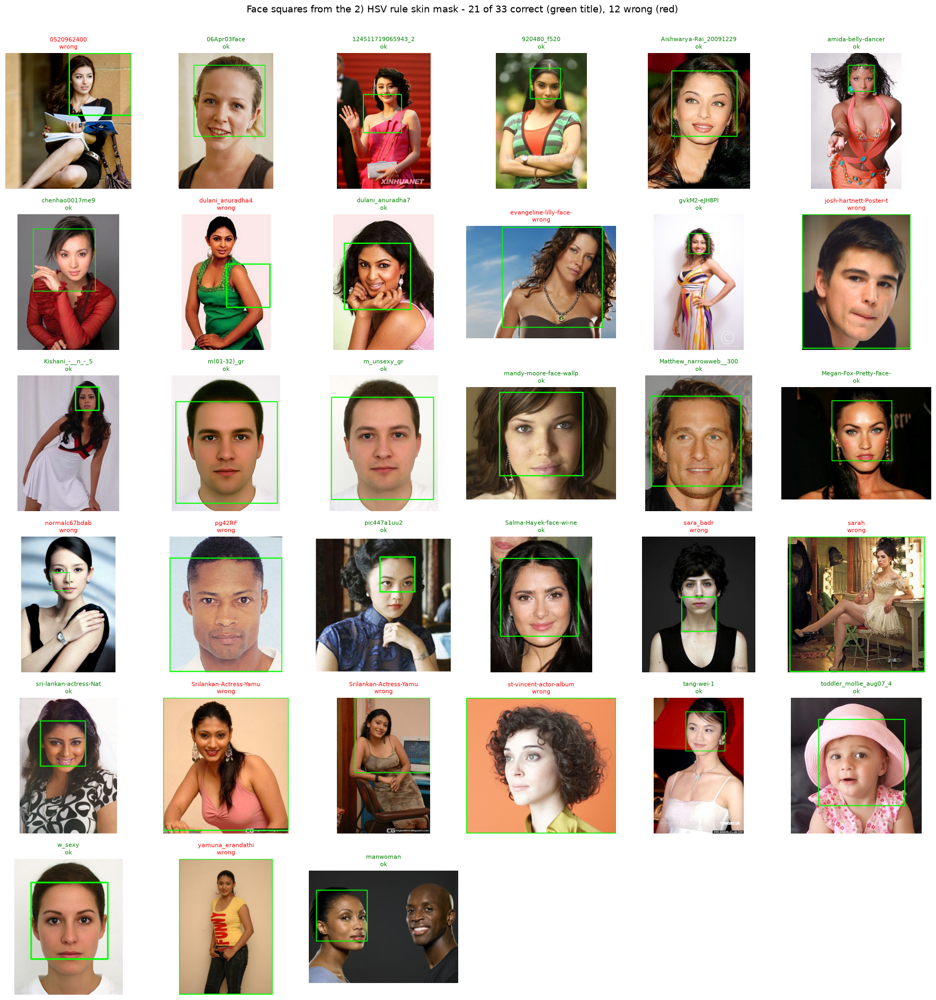

In [24]:
# visual check from RESULTS.md: the square frames the face correctly on these images (green title)
GOOD_BY_EYE = {
    '06Apr03Face', '124511719065943_2', '920480_f520', 'Aishwarya-Rai_20091229_aatheory',
    'amida-belly-dancer', 'dulani_anuradha7', 'Kishani_-__n_-_5', 'm(01-32)_gr', 'm_unsexy_gr',
    'mandy-moore-face-wallpapers_1913_1600', 'Matthew_narrowweb__300x381,0',
    'Megan-Fox-Pretty-Face-1-1024x768', 'Salma-Hayek-face-wi-new-lg',
    'sri-lankan-actress-Natasha-Perera-', 'tang-wei-1', 'toddler_mollie_aug07_400', 'w_sexy',
    'manwoman', 'chenhao0017me9', 'gvkM2-eJH8Pl', 'pic447a1uu2',
}

found = sum(1 for f in faces.values() if f[3] is not None)
good = sum(1 for name in faces if name in GOOD_BY_EYE)
print(f'square drawn on {found} of {len(faces)} images')
print(f'face framed correctly (visual check): {good}, missed or wrong: {len(faces) - good}')


def show_face_grid(picture_index, title, cmap=None):
    per_row = 6
    rows = int(np.ceil(len(faces) / per_row))
    fig, axs = plt.subplots(rows, per_row, figsize=(18, 3.2 * rows))
    for ax in axs.ravel():
        ax.axis('off')
    for ax, (name, f) in zip(axs.ravel(), faces.items()):
        picture = f[picture_index]
        ax.imshow(bgr_to_rgb(picture) if picture.ndim == 3 else picture, cmap=cmap)
        ok = name in GOOD_BY_EYE
        ax.set_title(f'{name[:22]}\n{"ok" if ok else "wrong"}', fontsize=8, color='green' if ok else 'red')
    fig.suptitle(title, fontsize=13)
    plt.tight_layout(rect=(0, 0, 1, 0.975))
    plt.show()


show_face_grid(4, f'Face squares from the {METHOD_TITLES[best_method]} skin mask - '
                  f'{good} of {len(faces)} correct (green title), {len(faces) - good} wrong (red)')

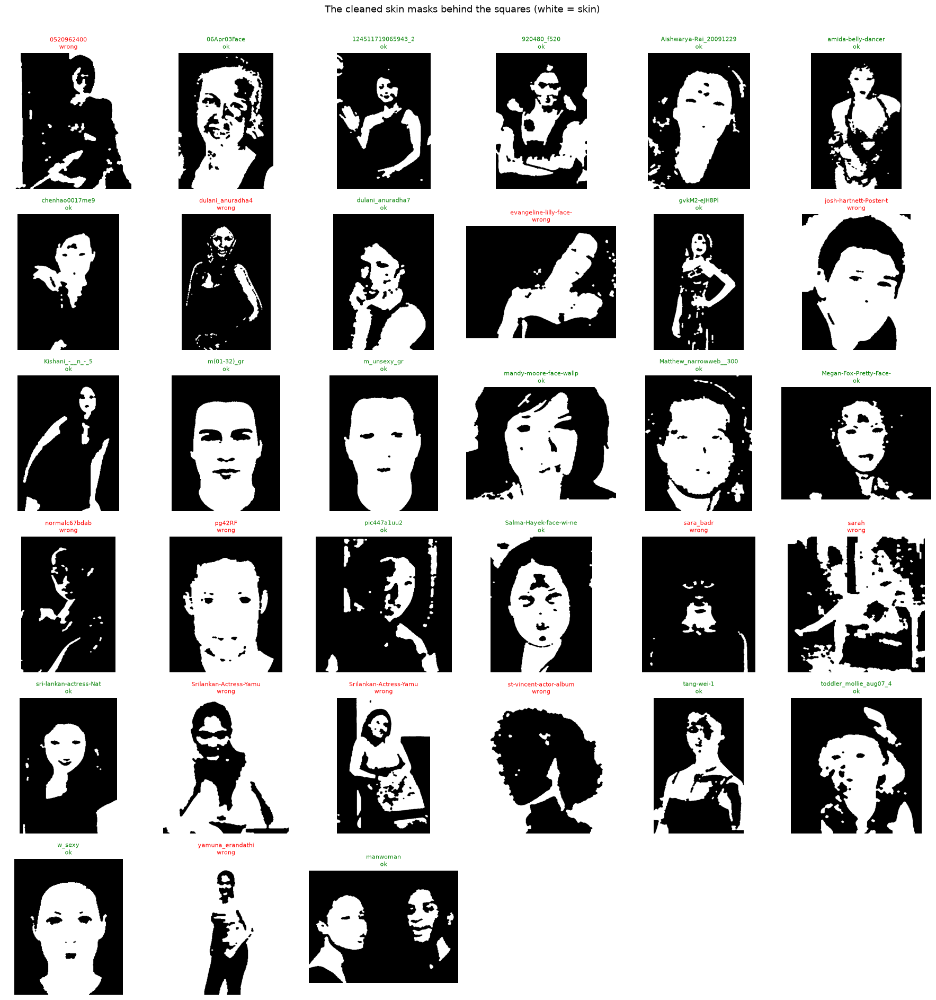

In [25]:
show_face_grid(2, 'The cleaned skin masks behind the squares (white = skin)', cmap='gray')

**Result:** a square is drawn on every image, and by eye it frames the face correctly on about **21 of 33**.
The 12 failures: a skin-coloured wall or poster merges with the face into one huge blob (8 images, e.g. `sarah`, `pg42RF`);
an arm is bigger than the face and wins the score (`dulani_anuradha4`, `evangeline-lilly`); over-exposed or very dark skin
gives a spotty mask, so only the eyes are framed (`normalc67bdab`, `sara_badr`). In `manwoman` only the woman is found,
because we keep a single blob. The top of the square is at the hair line, since the HSV mask has no hair.

---

### Conclusions

- Simple colour thresholds find skin quickly, but they also accept anything with a skin-like colour (walls, wood, orange clothes).
- On Pratheepan the HSV rule has the best accuracy (0.825) because it gives the fewest false positives; Kolkur (0.818) has the best F1 (0.611).
- Accuracy is dominated by the non-skin pixels (about 83% of the data), so precision and recall tell more than accuracy alone.
- The face square from the skin mask works on about 21 of 33 portraits; it fails when the background has skin colour or an arm is larger than the face.
- A trained colour model or a real face detector would be needed for reliable results.